In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr

In [2]:
# Load Penguins dataset
df = sns.load_dataset("penguins")

# Display first five rows
print(df.head())

# Dataset information
print(df.info())

# Statistical summary
print(df.describe())

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  

In [3]:
# Check missing values
print(df.isnull().sum())

# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Remove rows containing missing numerical values
numeric_df = numeric_df.dropna()

# Check the cleaned dataset
print("Shape:", numeric_df.shape)
print(numeric_df.head())

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
Shape: (342, 4)
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0            39.1           18.7              181.0       3750.0
1            39.5           17.4              186.0       3800.0
2            40.3           18.0              195.0       3250.0
4            36.7           19.3              193.0       3450.0
5            39.3           20.6              190.0       3650.0


In [4]:
##Pearson correlation measures the strength and direction of a linear relationship between two numerical variables.

# Calculate Pearson correlation matrix
pearson_matrix = numeric_df.corr(method="pearson")

print(pearson_matrix)

                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm           1.000000      -0.235053           0.656181   
bill_depth_mm           -0.235053       1.000000          -0.583851   
flipper_length_mm        0.656181      -0.583851           1.000000   
body_mass_g              0.595110      -0.471916           0.871202   

                   body_mass_g  
bill_length_mm        0.595110  
bill_depth_mm        -0.471916  
flipper_length_mm     0.871202  
body_mass_g           1.000000  


In [5]:
##Spearman measures the strength and direction of a monotonic relationship using ranked values.

##It can detect relationships that aren't necessarily linear.

# Calculate Spearman correlation matrix
spearman_matrix = numeric_df.corr(method="spearman")

print(spearman_matrix)

                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm           1.000000      -0.221749           0.672772   
bill_depth_mm           -0.221749       1.000000          -0.523267   
flipper_length_mm        0.672772      -0.523267           1.000000   
body_mass_g              0.583800      -0.432372           0.839974   

                   body_mass_g  
bill_length_mm        0.583800  
bill_depth_mm        -0.432372  
flipper_length_mm     0.839974  
body_mass_g           1.000000  


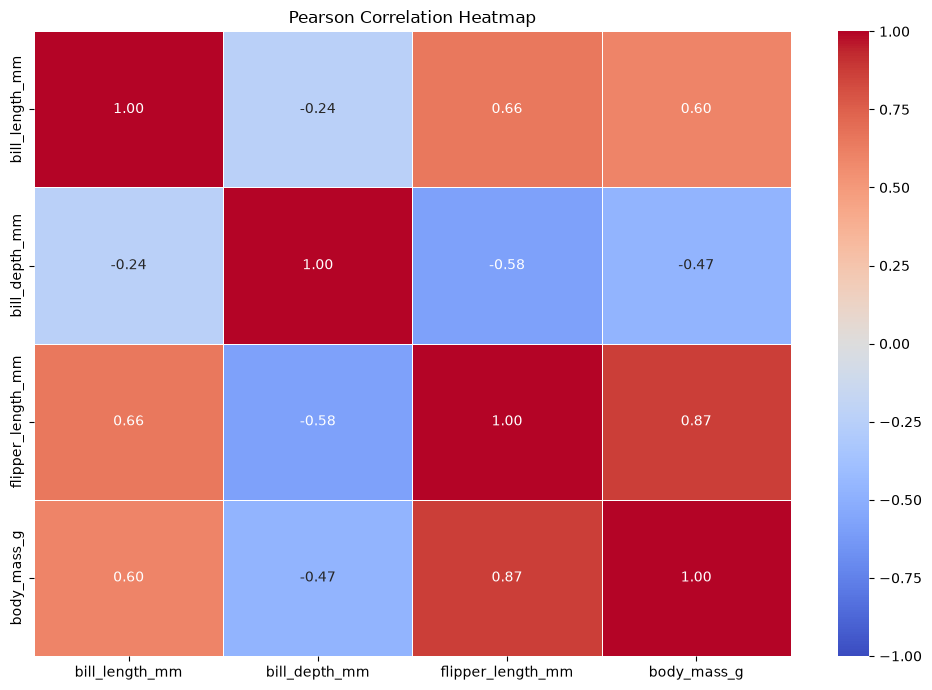

In [6]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    pearson_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()

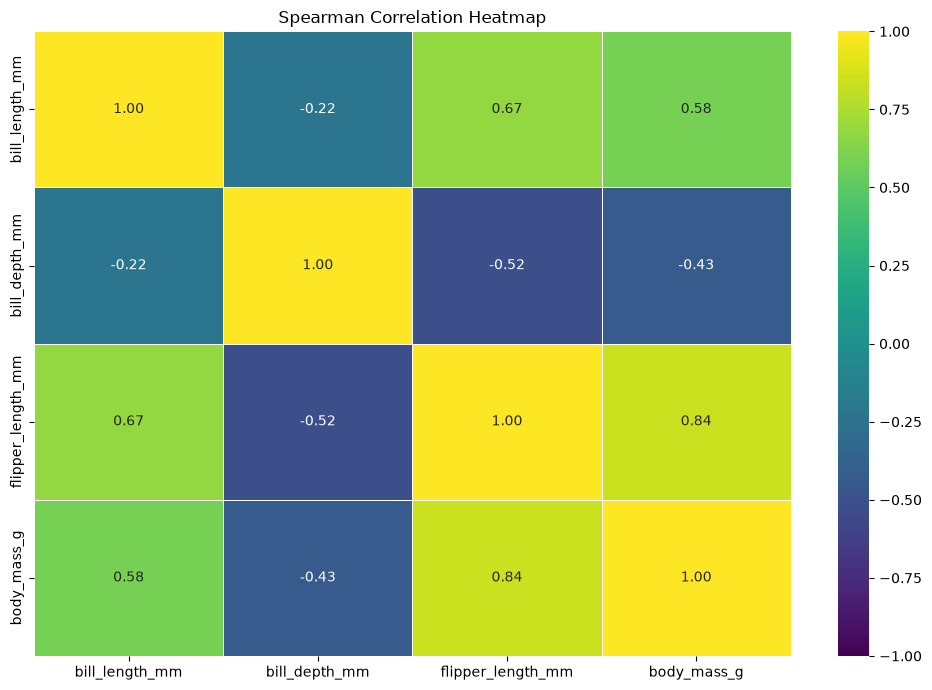

In [7]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    spearman_matrix,
    annot=True,
    cmap="viridis",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
##Now let's compare two specific variables: flipper length and body mass.

x = numeric_df["flipper_length_mm"]
y = numeric_df["body_mass_g"]

# Calculate Pearson correlation
pearson_corr, pearson_p = pearsonr(x, y)

# Calculate Spearman correlation
spearman_corr, spearman_p = spearmanr(x, y)

print("Pearson Correlation:", pearson_corr)
print("Pearson P-value:", pearson_p)

print("Spearman Correlation:", spearman_corr)
print("Spearman P-value:", spearman_p)

##A p-value helps us assess statistical evidence against the hypothesis that the population correlation is zero.

#For a significance level of 0.05:
#- p < 0.05: Statistically significant evidence of correlation.
#- p >= 0.05: Insufficient evidence to establish a non-zero correlation.

Pearson Correlation: 0.8712017673060113
Pearson P-value: 4.3706809630006207e-107
Spearman Correlation: 0.8399741230312999
Spearman P-value: 2.763218997179657e-92


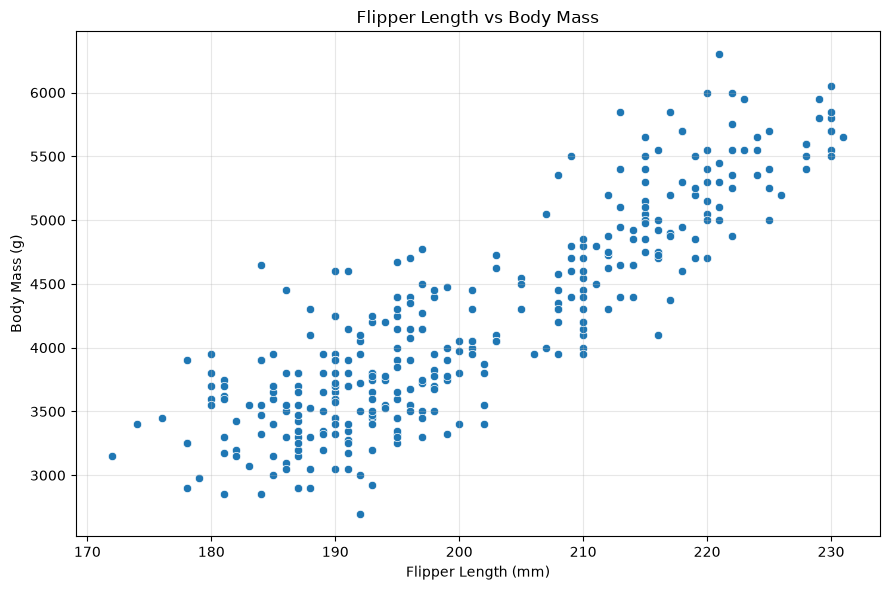

In [9]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=numeric_df,
    x="flipper_length_mm",
    y="body_mass_g"
)

plt.title("Flipper Length vs Body Mass")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

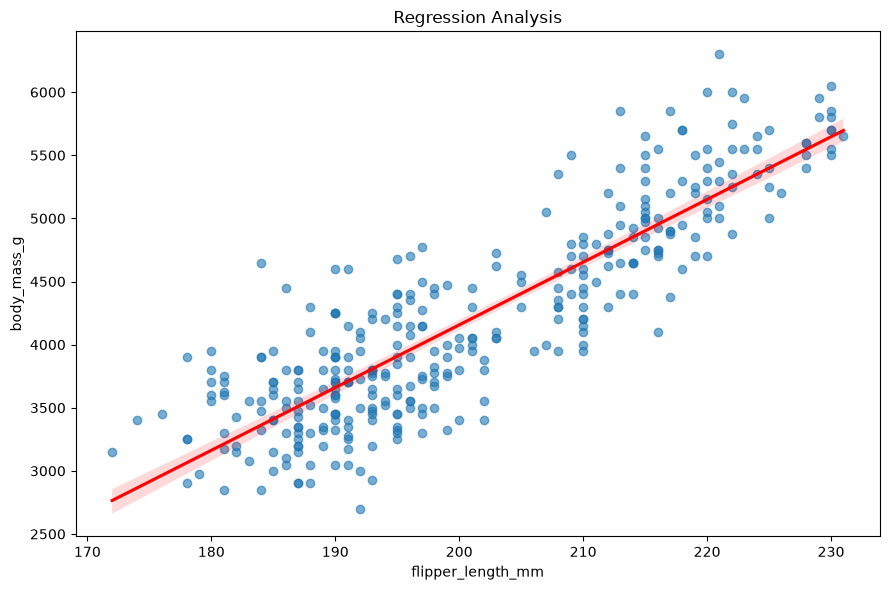

In [10]:
#Now we'll add a regression line to the scatter plot.

plt.figure(figsize=(9, 6))

sns.regplot(
    data=numeric_df,
    x="flipper_length_mm",
    y="body_mass_g",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Regression Analysis")
plt.tight_layout()
plt.show()